# Extension - feature audit and leakage sensitivity of the tuned model

**Question.** Do the excluded fields really matter, and what would each one do to the tuned model?

**Brief and report.** Part D, with the leakage discussion in Parts A and C. Report Section 4.1. Training CV only.

The setup cell below makes the repository root the working folder, so `src/` can be imported, and defines two helpers: `results(name)` reads a table from `results/` and `show(...)` displays saved figures from `reports/figures/`.

In [1]:
import os, sys
from pathlib import Path
root = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
sys.path.insert(0, str(root))
os.chdir(root)
import pandas as pd
from IPython.display import Image, Markdown, display
from src.common import ROOT
pd.set_option('display.precision', 3)
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 200)

def show(*names):
    """Display saved figures from reports/figures/."""
    for name in names:
        display(Markdown(f'**reports/figures/{name}**'))
        display(Image(filename=str(ROOT / 'reports' / 'figures' / name)))

def results(name):
    return pd.read_csv(ROOT / 'results' / name)

`feature_audit()` in `src/features.py` does three things:
1. Records, for every field, its role and the reason it is kept or excluded.
2. With the tuned gradient boosting model, adds each excluded field back, or removes a kept candidate, one at a time.
3. Compares each change with the chosen feature set on the same folds, with corrected intervals.

**How to read the output.** A large gain from adding a field back is a warning sign, not a reason to use it: the gain comes from information that is not available at booking time.

Feature audit | sensitivity: tuned HGB, final feature set: AP 0.687


Feature audit | sensitivity: tuned HGB, add back country: AP 0.761


Feature audit | sensitivity: tuned HGB, add back required_car_parking_spaces: AP 0.710


Feature audit | sensitivity: tuned HGB, add back deposit_type: AP 0.698


Feature audit | sensitivity: tuned HGB, add back arrival_date_year: AP 0.701


Feature audit | sensitivity: tuned HGB, remove total_of_special_requests: AP 0.611


Feature audit | sensitivity: tuned HGB, remove adr: AP 0.683


,feature,meaning,role,decision,evidence
0,hotel,City hotel or resort hotel,booking-time field,kept,
1,is_canceled,"Target: 1 if the booking was cancelled, 0 othe...",target,"predicted, never an input",
2,lead_time,Days between entering the booking and the arri...,booking-time field,kept,
3,arrival_date_year,Year of arrival,leakage candidate (rule c),excluded,Each year occurs once; a future booking always...
4,arrival_date_month,Month of arrival,booking-time field,kept,
5,arrival_date_week_number,Week number of arrival,booking-time field,kept,
6,arrival_date_day_of_month,Day of the month of arrival,booking-time field,kept,
7,stays_in_weekend_nights,Booked weekend nights (Saturday or Sunday),booking-time field,kept,
8,stays_in_week_nights,Booked week nights (Monday to Friday),booking-time field,kept,
9,adults,Number of adults,booking-time field,kept,


,configuration,mean,sd,ci_low,ci_high,p_value,n,validation_train_ratio
0,final feature set,0.687,0.006,0.675,0.699,9.309e-09,5,0.25
1,add back country,0.761,0.005,0.752,0.770,2.222e-09,5,0.25
2,add back required_car_parking_spaces,0.710,0.009,0.693,0.727,3.446e-08,5,0.25
3,add back deposit_type,0.698,0.007,0.684,0.711,1.398e-08,5,0.25
4,add back arrival_date_year,0.701,0.006,0.690,0.712,6.058e-09,5,0.25
5,remove total_of_special_requests,0.611,0.007,0.599,0.623,1.687e-08,5,0.25
6,remove adr,0.683,0.007,0.669,0.696,1.562e-08,5,0.25


,option,reference,mean,sd,ci_low,ci_high,p_value,n,validation_train_ratio,p_holm
0,add back country,final feature set,0.074,3.593e-03,0.067,0.080,6.775e-06,5,0.25,3.387e-05
1,add back required_car_parking_spaces,final feature set,0.022,3.774e-03,0.015,0.029,8.932e-04,5,0.25,2.251e-03
2,add back deposit_type,final feature set,0.010,1.673e-03,0.007,0.014,7.503e-04,5,0.25,2.251e-03
3,add back arrival_date_year,final feature set,0.013,9.972e-04,0.012,0.015,3.656e-05,5,0.25,1.463e-04
4,remove total_of_special_requests,final feature set,-0.076,1.466e-03,-0.079,-0.074,1.657e-07,5,0.25,9.940e-07
5,remove adr,final feature set,-0.005,1.273e-03,-0.007,-0.002,4.900e-03,5,0.25,4.900e-03


**reports/figures/fig_A_01_availability.png**

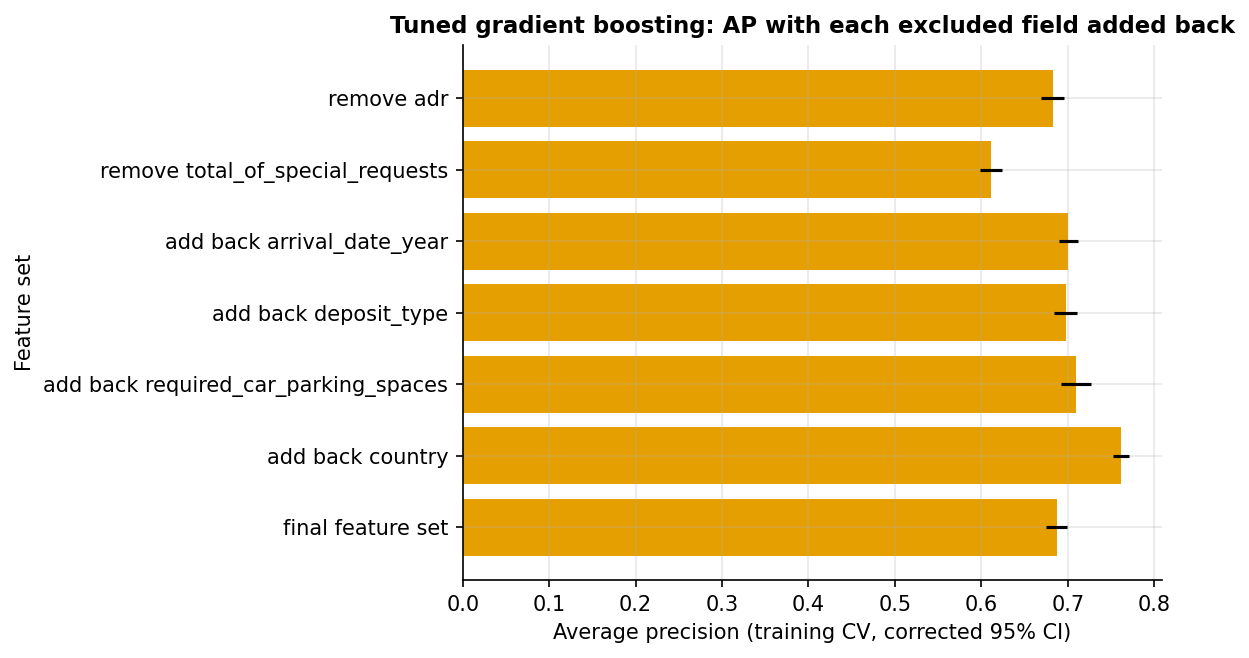

In [2]:
from src.features import feature_audit
audit, summary, comparison = feature_audit()
display(audit)
display(summary)
display(comparison)
show('fig_A_01_availability.png')